# 01 — Historical Data Understanding
## Online Retail II | E-Commerce Analytics

**Objective:** Establish a reproducible, source-faithful understanding of the real transaction history before designing Shopify simulation logic, cleaning rules, RDS tables, or analytics models.

**Source:** UCI Machine Learning Repository, *Online Retail II* (two annual worksheets, December 2009–December 2011).

**Important:** Each source row represents an **invoice line**, not necessarily a distinct order. Invoice cancellations, anonymous purchases, non-product stock codes, and customer ID continuity require investigation.

**Workflow:** Load → inspect schema → profile source quality → characterize invoices and customer identifiers → check timeline → document modeling decisions.

No rows are removed in this notebook. Derived classification fields are for exploration only.

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Load the historical Excel workbook
file_path = "../data/raw/online_retail_II.xlsx"
sheets = pd.read_excel(file_path, sheet_name=None)

for name, sheet in sheets.items():
    print(f"{name}: {sheet.shape}")
    display(sheet.head())

# Combine both years and retain their source
frames = sheets
raw = pd.concat(
    [
        sheet.assign(source_sheet=name)
        for name, sheet in sheets.items()
    ],
    ignore_index=True
)

print(f"Combined dataset: {raw.shape}")


Year 2009-2010: (525461, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


Year 2010-2011: (541910, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Combined dataset: (1067371, 9)


## 1. Source schema and examples
Invoice codes and stock codes are **identifiers**, not numeric quantities. Preserve leading zeros and alphanumeric prefixes. Customer IDs should not be treated as a continuously assigned numeric measure.

In [3]:
schema = pd.DataFrame({
    "source_dtype": raw.dtypes.astype(str),
    "missing_rows": raw.isna().sum(),
    "missing_percent": raw.isna().mean().mul(100).round(2),
    "distinct_values": raw.nunique(dropna=True),
})
display(schema)
display(raw.head(8))


,source_dtype,missing_rows,missing_percent,distinct_values
Invoice,object,0,0.00,53628
StockCode,object,0,0.00,5305
Description,object,4382,0.41,5698
Quantity,int64,0,0.00,1057
InvoiceDate,datetime64[us],0,0.00,47635
Price,float64,0,0.00,2807
Customer ID,float64,243007,22.77,5942
Country,str,0,0.00,43
source_sheet,str,0,0.00,2


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,source_sheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,Year 2009-2010
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,Year 2009-2010
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085.0,United Kingdom,Year 2009-2010
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,Year 2009-2010
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085.0,United Kingdom,Year 2009-2010


## 2. Preserve identifiers and classify source rows
Classification is **provisional**:
- `Invoice` beginning with `C` is a cancellation candidate.
- Nonpositive quantity/price require review; they are not automatically errors.
- Missing customer ID means the record cannot directly support customer-level retention.
- Duplicate invoice numbers across worksheets need a check before choosing an order key.

In [4]:
df = raw.copy()
df["invoice_id"] = df["Invoice"].astype("string").str.strip()
df["stock_code"] = df["StockCode"].astype("string").str.strip()
df["customer_id"] = df["Customer ID"].astype("Int64").astype("string")
df["invoice_timestamp"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["line_amount"] = df["Quantity"] * df["Price"]
df["is_cancellation_code"] = df["invoice_id"].str.upper().str.startswith("C", na=False)
df["has_customer_id"] = df["customer_id"].notna()
df["positive_sale_line"] = (
    (~df["is_cancellation_code"])
    & df["Quantity"].gt(0)
    & df["Price"].gt(0)
)
display(df[["Invoice", "invoice_id", "StockCode", "stock_code", "Customer ID", "customer_id"]].head())


,Invoice,invoice_id,StockCode,stock_code,Customer ID,customer_id
0,489434,489434,85048,85048,13085.0,13085
1,489434,489434,79323P,79323P,13085.0,13085
2,489434,489434,79323W,79323W,13085.0,13085
3,489434,489434,22041,22041,13085.0,13085
4,489434,489434,21232,21232,13085.0,13085


In [5]:
quality = pd.DataFrame({
    "metric": [
        "Invoice lines", "Missing customer ID lines",
        "Missing product description lines", "Invalid invoice date lines",
        "Cancellation-code lines", "Cancellation-code unique invoices",
        "Nonpositive quantity lines", "Nonpositive unit price lines",
        "Exact duplicate source rows", "Candidate positive-sale lines",
    ],
    "count": [
        len(df),
        df["customer_id"].isna().sum(),
        df["Description"].isna().sum(),
        df["invoice_timestamp"].isna().sum(),
        df["is_cancellation_code"].sum(),
        df.loc[df["is_cancellation_code"], "invoice_id"].nunique(),
        df["Quantity"].le(0).sum(),
        df["Price"].le(0).sum(),
        raw.duplicated().sum(),
        df["positive_sale_line"].sum(),
    ],
})
quality["percent_of_lines"] = np.where(
    quality["metric"].str.contains("lines|rows", case=False),
    (quality["count"] / len(df) * 100).round(2),
    np.nan,
)
display(quality)


,metric,count,percent_of_lines
0,Invoice lines,1067371,100.00
1,Missing customer ID lines,243007,22.77
2,Missing product description lines,4382,0.41
3,Invalid invoice date lines,0,0.00
4,Cancellation-code lines,19494,1.83
5,Cancellation-code unique invoices,8292,NaN
6,Nonpositive quantity lines,22950,2.15
7,Nonpositive unit price lines,6207,0.58
8,Exact duplicate source rows,12133,1.14
9,Candidate positive-sale lines,1041670,97.59


## 3. Temporal coverage and annual-sheet overlap
The two sheets overlap around December 2010. We must **check** duplicated source records, cross-sheet invoice IDs, and customer identities rather than assuming worksheets form disjoint populations.

In [6]:
timeline = df.groupby("source_sheet", dropna=False).agg(
    lines=("invoice_id", "size"),
    first_timestamp=("invoice_timestamp", "min"),
    last_timestamp=("invoice_timestamp", "max"),
    distinct_invoices=("invoice_id", "nunique"),
    distinct_customers=("customer_id", "nunique"),
    distinct_stock_codes=("stock_code", "nunique"),
).reset_index()
display(timeline)

sheet_names = list(frames)
if len(sheet_names) == 2:
    a, b = (df.loc[df["source_sheet"].eq(n)] for n in sheet_names)
    print("Customer IDs present in BOTH sheets:", len(
        set(a["customer_id"].dropna()) & set(b["customer_id"].dropna())
    ))
    print("Invoice IDs present in BOTH sheets:", len(
        set(a["invoice_id"].dropna()) & set(b["invoice_id"].dropna())
    ))


,source_sheet,lines,first_timestamp,last_timestamp,distinct_invoices,distinct_customers,distinct_stock_codes
0,Year 2009-2010,525461,2009-12-01 07:45:00,2010-12-09 20:01:00,28816,4383,4631
1,Year 2010-2011,541910,2010-12-01 08:26:00,2011-12-09 12:50:00,25900,4372,4070


Customer IDs present in BOTH sheets: 2813
Invoice IDs present in BOTH sheets: 1088


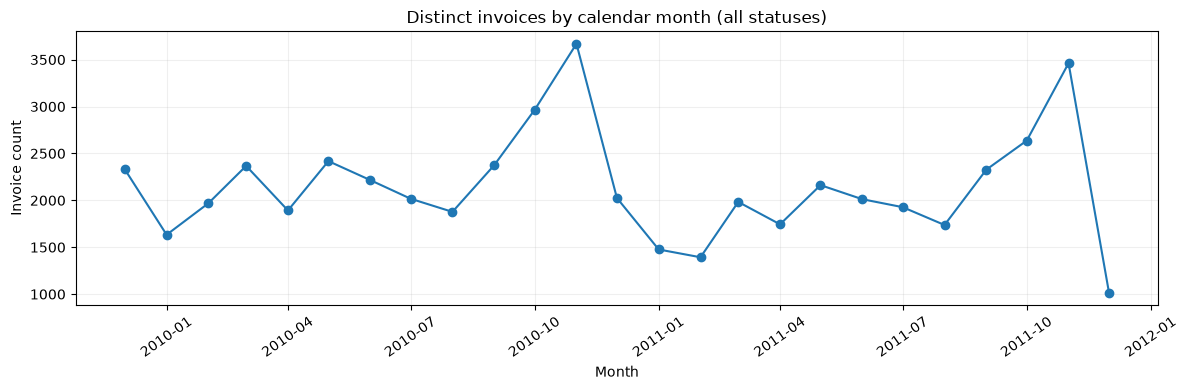

In [7]:
monthly_lines = (
    df.dropna(subset=["invoice_timestamp"])
      .assign(month=lambda x: x["invoice_timestamp"].dt.to_period("M").dt.to_timestamp())
      .groupby("month", as_index=False)
      .agg(lines=("invoice_id", "size"), invoices=("invoice_id", "nunique"))
)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(monthly_lines["month"], monthly_lines["invoices"], marker="o", linewidth=1.5)
ax.set(title="Distinct invoices by calendar month (all statuses)", xlabel="Month", ylabel="Invoice count")
ax.grid(alpha=.2)
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()


## 4. Invoice structure and customer continuity
An invoice usually comprises several source rows. First inspect counts at the **invoice level**; only then define a qualifying purchase.

The same customer may have multiple invoices. For retention analysis, customers with missing IDs are excluded from *customer metrics* but **not removed from the raw dataset**.

In [8]:
invoice_summary = df.groupby("invoice_id", dropna=False).agg(
    lines=("invoice_id", "size"),
    distinct_products=("stock_code", "nunique"),
    invoice_time_min=("invoice_timestamp", "min"),
    invoice_time_max=("invoice_timestamp", "max"),
    customer_count=("customer_id", "nunique"),
    quantity_sum=("Quantity", "sum"),
    signed_amount=("line_amount", "sum"),
    cancellation_candidate=("is_cancellation_code", "max"),
).reset_index()
display(invoice_summary.describe(include="all").T)
print("Invoices referencing multiple customer IDs:", 
      int(invoice_summary["customer_count"].gt(1).sum()))


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
invoice_id,53628,53628,489434,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lines,53628.0,NaN,NaN,NaN,19.903241,1.0,2.0,9.0,23.0,1350.0,41.252573
distinct_products,53628.0,NaN,NaN,NaN,19.046468,1.0,1.0,9.0,22.0,1110.0,37.84445
invoice_time_min,53628,NaN,NaN,NaN,2010-12-14 17:33:00.606399,2009-12-01 07:45:00,2010-06-10 12:13:30,2010-11-23 15:40:30,2011-06-26 14:06:30,2011-12-09 12:50:00,NaN
invoice_time_max,53628,NaN,NaN,NaN,2010-12-14 17:33:00.712687,2009-12-01 07:45:00,2010-06-10 12:13:30,2010-11-23 15:40:30,2011-06-26 14:06:30,2011-12-09 12:50:00,NaN
customer_count,53628.0,NaN,NaN,NaN,0.836802,0.0,1.0,1.0,1.0,1.0,0.36955
quantity_sum,53628.0,NaN,NaN,NaN,197.81629,-87167.0,2.0,93.0,233.0,87167.0,1234.716062
signed_amount,53628.0,NaN,NaN,NaN,359.648888,-168469.6,0.0,196.345,403.6525,168469.6,1654.829288
cancellation_candidate,53628,2,False,45336,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Invoices referencing multiple customer IDs: 0


In [9]:
# Exploratory definition only: unique invoices containing ≥1 positive-quantity, positive-price,
# non-cancellation line and a non-null customer ID. We will refine after cancellation review.
purchase_lines = df.loc[
    df["positive_sale_line"] & df["has_customer_id"] & df["invoice_timestamp"].notna()
].copy()

customer_purchases = (
    purchase_lines[["customer_id", "invoice_id", "invoice_timestamp"]]
    .drop_duplicates(["customer_id", "invoice_id"])
)
counts = customer_purchases.groupby("customer_id")["invoice_id"].nunique()
overview = pd.Series({
    "distinct identifiable purchasers": len(counts),
    "one-invoice purchasers": int(counts.eq(1).sum()),
    "repeat purchasers (>=2 invoices)": int(counts.ge(2).sum()),
    "repeat purchaser proportion (%)": round(100 * counts.ge(2).mean(), 2),
    "max distinct invoices per purchaser": int(counts.max()),
})
display(overview.to_frame("value"))


,value
distinct identifiable purchasers,5878.00
one-invoice purchasers,1623.00
repeat purchasers (>=2 invoices),4255.00
repeat purchaser proportion (%),72.39
max distinct invoices per purchaser,398.00


## 5. Source anomalies to investigate
Before trusting invoice totals or calibrating customer purchase frequency, examine:
1. Cancellation invoices (including potential linked original invoices).
2. Special stock codes (postage, discounts, fees and adjustments).
3. Zero and negative unit prices and quantities.
4. Potential wholesale customers and extreme basket sizes.
5. Exact duplicate rows versus legitimate repeated identical invoice lines.


In [10]:
display(df.loc[
    df["Quantity"].le(0) | df["Price"].le(0) | df["is_cancellation_code"],
    ["invoice_id", "stock_code", "Description", "Quantity", "Price", "customer_id", "invoice_timestamp"]
].head(20))
display(
    df.groupby("stock_code", dropna=False).agg(
        lines=("stock_code", "size"),
        descriptions=("Description", "nunique"),
        total_quantity=("Quantity", "sum")
    ).sort_values("lines", ascending=False).head(20)
)


,invoice_id,stock_code,Description,Quantity,Price,customer_id,invoice_timestamp
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2.95,16321,2009-12-01 10:33:00
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,1.65,16321,2009-12-01 10:33:00
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,4.25,16321,2009-12-01 10:33:00
181,C489449,21896,POTTING SHED TWINE,-6,2.10,16321,2009-12-01 10:33:00
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2.95,16321,2009-12-01 10:33:00
183,C489449,21871,SAVE THE PLANET MUG,-12,1.25,16321,2009-12-01 10:33:00
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,1.25,16321,2009-12-01 10:33:00
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,0.85,16321,2009-12-01 10:33:00
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2.95,16321,2009-12-01 10:33:00
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,4.25,17592,2009-12-01 10:44:00


,lines,descriptions,total_quantity
stock_code,,,
85123A,5829,5,96066
22423,4424,7,25764
85099B,4216,4,95739
21212,3318,2,95450
20725,3259,2,40011
84879,2960,3,80705
47566,2768,2,27291
21232,2747,2,38033
22197,2549,3,79363


## 6. Data dictionary and EDA decisions

| Source column | Source interpretation | Modeling note |
|---|---|---|
| `Invoice` | Invoice/order transaction reference | Preserve as string; identify cancellation prefixes |
| `StockCode` | Item code | Can include non-merchandise codes |
| `Description` | Item description | May vary or be missing |
| `Quantity` | Signed line quantity | Investigate returns/cancellations |
| `InvoiceDate` | Original transaction timestamp | Preserve original; simulation time is distinct |
| `Price` | Unit price | Review zero-price and adjustments |
| `Customer ID` | Source customer key | Missing for some lines; do not invent identities |
| `Country` | Transaction country | Check distribution and consistency |

### Decisions deliberately deferred
- Confirm a canonical key for cross-sheet invoices and rows.
- Define an eligible purchase and cancellation/refund semantics.
- Define an anonymized source→Shopify identity map.
- Decide whether to retain wholesale-like customers in the simulation.
- Compare old historical dates against the simulated 2026+ timeline.
- Specify safeguards against duplicate generation and future-data leakage.

**Next notebook:** `02_data_quality.ipynb` — detailed data-quality rules and repeatable cleaning tests.

**Then:** customer purchase behavior, cohort retention, RFM, purchase intervals, and product demand before calibrating the Shopify event generator.
